![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Feature Engineering and Model Tuning
*Data Science & Machine Learning - Week 5, Day 1*

## How to use this notebook

Last week you trained models on data that was mostly ready to use, with their default settings. Today is about the two things that usually decide how good a model is: **the features you give it** and **the settings you choose for it**. You will also meet the tool that keeps both honest, the scikit-learn **pipeline**.

The slides go with the notebook: **7. Feature engineering** and **6A2. Hyperparameters & pipelines** (in the `s-409` folder) with sections 1 to 6, then **9. Cross Validation** and **9A. Imbalanced Datasets** (in this folder) with sections 7 to 9.

The data files are in the `data/` folder next to this notebook, so download or clone the whole `s-410` folder. Run the cells in order.

## Table of contents

- [Setup](#Setup)
- [1. What feature engineering is](#1.-What-feature-engineering-is)
- [2. Encoding categories and filling gaps](#2.-Encoding-categories-and-filling-gaps)
    - [Missing does not always mean unknown](#Missing-does-not-always-mean-unknown)
    - [One-hot encoding](#One-hot-encoding)
- [3. Scaling](#3.-Scaling)
- [4. Redundant features](#4.-Redundant-features)
- [5. Creating features from what you know](#5.-Creating-features-from-what-you-know)
- [6. Pipelines: every step in one object](#6.-Pipelines:-every-step-in-one-object)
- [7. Overfitting and the validation curve](#7.-Overfitting-and-the-validation-curve)
- [8. Tuning hyperparameters](#8.-Tuning-hyperparameters)
    - [Grid search](#Grid-search)
    - [A grid on several hyperparameters](#A-grid-on-several-hyperparameters)
    - [Random search](#Random-search)
- [9. Imbalanced data](#9.-Imbalanced-data)
    - [Stratify every split](#Stratify-every-split)
    - [Score with a metric that sees the rare class](#Score-with-a-metric-that-sees-the-rare-class)
    - [Class weights](#Class-weights)
    - [Moving the threshold](#Moving-the-threshold)
    - [Resampling](#Resampling)
- [Summary: what to do when](#Summary:-what-to-do-when)
- [Appendix](#Appendix)
    - [A.1 Ordinal encoding and binning](#A.1-Ordinal-encoding-and-binning)
    - [A.2 Learning curves: would more data help?](#A.2-Learning-curves:-would-more-data-help?)
    - [A.3 Training error and generalisation error](#A.3-Training-error-and-generalisation-error)

## Setup

The imports for the whole notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import (train_test_split, cross_val_score, KFold, StratifiedKFold,
                                     validation_curve, learning_curve, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (root_mean_squared_error, accuracy_score, recall_score, precision_score,
                             f1_score, balanced_accuracy_score, confusion_matrix)

## 1. What feature engineering is

A model only sees the columns you give it. **Feature engineering** is everything you do to those columns before training:

+ **Encoding:** turning text categories into numbers the model can use.
+ **Handling missing values:** deciding what a gap in the data means.
+ **Scaling:** putting features on comparable ranges.
+ **Selecting:** dropping features that add noise or repeat each other.
+ **Creating:** building new features from what you know about the problem.

None of these change the algorithm, and yet each can matter more than which algorithm you choose. The first part of the lesson shows each one on a small dataset.

## 2. Encoding categories and filling gaps

`data/salaries.csv` combines a company's HR file with a medical exam for 200 employees. The goal is to predict `Salary`.

In [2]:
salary = pd.read_csv("data/salaries.csv")
print(salary.shape)
salary.head()

(200, 11)


,Salary,Experience,Gender,Height,Weight,Flexibility,Strenght,BMI,BirthC,Daltonic,Estrogen
0,32064.17357,Senior,Female,160.189080,60.110733,230.467496,227.262099,16.748028,1,NaN,74.619024
1,17160.86833,Junior,Female,153.100363,61.932449,260.080909,244.758004,17.101780,1,NaN,74.581776
2,30940.22480,Senior,Female,166.949128,58.109921,237.047355,236.998125,17.085108,1,NaN,85.510909
3,21036.86527,Junior,Male,173.952647,75.975594,151.578682,287.952815,21.061525,0,Dychromassy,22.091243
4,18855.00061,Junior,Male,180.282763,75.418624,152.502660,283.185533,21.134343,0,Dychromassy,21.749843


In [3]:
salary.isna().sum()[salary.isna().sum() > 0]

Daltonic    99
dtype: int64

### Missing does not always mean unknown

`Daltonic` (colour blindness) is empty for 99 employees. The other values are the two types of colour blindness, so an empty cell here almost certainly means "not colour-blind". Filling it with the mean or dropping the rows would be wrong: the gap *is* information. Always ask what a missing value means before choosing how to fill it.

In [4]:
salary["Daltonic"] = salary["Daltonic"].fillna("None")
salary["Daltonic"].value_counts()

Daltonic
None             99
Dychromassy      53
Monochromassy    48
Name: count, dtype: int64

### One-hot encoding

`Experience`, `Gender` and `Daltonic` are text. `pd.get_dummies` turns each category into its own 0/1 column; `drop_first=True` drops one column per feature, because it can always be inferred from the others (if you are not Junior, you are Senior).

In [5]:
X = pd.get_dummies(salary.drop(columns="Salary"), drop_first=True)
y = salary["Salary"]
X.head()

,Height,Weight,Flexibility,Strenght,BMI,BirthC,Estrogen,Experience_Senior,Gender_Male,Daltonic_Monochromassy,Daltonic_None
0,160.189080,60.110733,230.467496,227.262099,16.748028,1,74.619024,True,False,False,True
1,153.100363,61.932449,260.080909,244.758004,17.101780,1,74.581776,False,False,False,True
2,166.949128,58.109921,237.047355,236.998125,17.085108,1,85.510909,True,False,False,True
3,173.952647,75.975594,151.578682,287.952815,21.061525,0,22.091243,False,True,False,False
4,180.282763,75.418624,152.502660,283.185533,21.134343,0,21.749843,False,True,False,False


Encoding categories as 0, 1, 2 instead (ordinal encoding) only makes sense when the categories have a natural order, like Junior < Senior or small < medium < large. For unordered categories such as regions, numbering them invents an order the model will take seriously. More on both, and on binning numbers into groups, in the appendix.

## 3. Scaling

We split once and compare everything against a baseline: predicting the average training salary for everyone.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

baseline_pred = np.full(len(y_test), y_train.mean())
print(f"Baseline RMSE: {root_mean_squared_error(y_test, baseline_pred):,.0f}")

Baseline RMSE: 5,643


In [7]:
knn = KNeighborsRegressor(n_neighbors=3).fit(X_train, y_train)
print(f"KNN on raw features: {root_mean_squared_error(y_test, knn.predict(X_test)):,.0f}")

KNN on raw features: 5,724


**KNN on the raw features is worse than the baseline.** Look at the ranges: `Flexibility` and `Strenght` are in the hundreds, while `Experience_Senior` is 0 or 1. KNN measures distance, so the large-valued columns decide who the neighbours are and the 0/1 columns barely count.

`MinMaxScaler` maps every feature to the range 0 to 1. It is **fitted on the training set only** and then applied to both sets, so nothing about the test set leaks into training.

In [8]:
X_train.describe().loc[["min", "max"]].round(1)

,Height,Weight,Flexibility,Strenght,BMI,BirthC,Estrogen
min,147.2,55.0,130.8,216.3,16.3,0.0,19.2
max,187.0,79.8,263.5,309.8,21.9,1.0,91.4


In [9]:
scaler = MinMaxScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

knn = KNeighborsRegressor(n_neighbors=3).fit(X_train_s, y_train)
print(f"KNN on scaled features: {root_mean_squared_error(y_test, knn.predict(X_test_s)):,.0f}")

KNN on scaled features: 3,699


Same model, same data: the error drops by about a third just because every feature now counts equally. Distance-based models (KNN, SVM) and models trained by gradient descent (logistic regression, neural networks) need scaling. Decision trees do not: they split one feature at a time, so its scale does not matter.

## 4. Redundant features

If two features carry the same information, a model sees it twice. For KNN that means it counts double in every distance. A correlation matrix of the scaled training features shows how much they overlap.

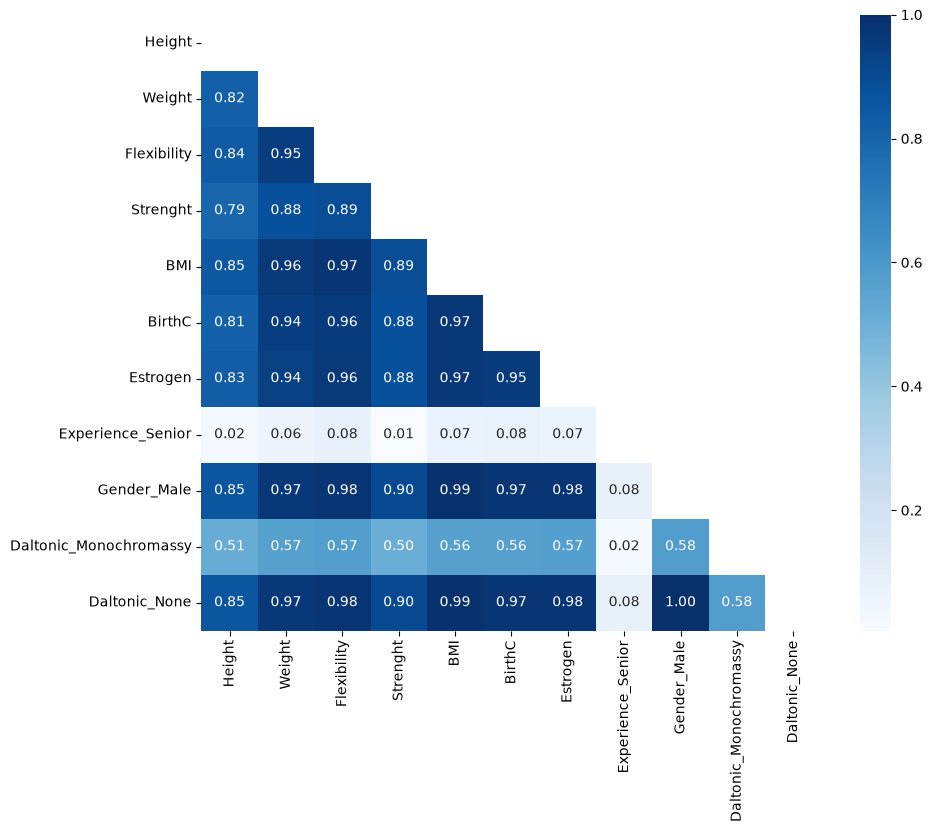

In [10]:
corr = pd.DataFrame(X_train_s, columns=X.columns).corr().abs()

mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="Blues", ax=ax)
plt.show()

Every body measurement is correlated 0.8 or more with `Gender_Male`, and with each other: in this dataset they are all, in effect, the same feature. Even `Daltonic_None` matches gender exactly (1.00): in this file every man is colour-blind and no woman is, a sign the data was simulated. `Experience_Senior` is the only one that tells us something different. Seven near-copies of gender drown out experience in every distance KNN computes.

Keeping only experience and gender:

In [11]:
keep = [X.columns.get_loc(c) for c in ["Experience_Senior", "Gender_Male"]]

knn = KNeighborsRegressor(n_neighbors=3).fit(X_train_s[:, keep], y_train)
print(f"KNN on 2 features: {root_mean_squared_error(y_test, knn.predict(X_test_s[:, keep])):,.0f}")

KNN on 2 features: 3,142


Two features beat eleven. More columns are not automatically better: every irrelevant or repeated feature is noise the model has to fight. A common rule of thumb is to drop one of any pair correlated above about 0.9, keeping the one that is easier to explain or measure.

## 5. Creating features from what you know

`data/energy_loss.csv` records the energy lost by wind turbines together with three readings: `Voltage`, `Rotation` and `Stability`. A linear regression on the raw readings:

In [12]:
energy = pd.read_csv("data/energy_loss.csv")
X_e = energy[["Voltage", "Rotation", "Stability"]]
y_e = energy["Loss"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_e, y_e, test_size=0.25, random_state=0)

reg = LinearRegression().fit(Xe_train, ye_train)
print(f"R² on raw readings: {reg.score(Xe_test, ye_test):.3f}")

R² on raw readings: 0.011


An R² near 0: the readings seem useless. But an engineer tells us each turbine has an **ideal** voltage (100), rotation (150) and stability (90), and that losses grow the further a reading is from its ideal, in either direction. A straight line cannot capture "too high and too low are both bad". The squared distance from the ideal can.

In [13]:
def deviations(df):
    return pd.DataFrame({
        "Voltage_dev": (df["Voltage"] - 100) ** 2,
        "Rotation_dev": (df["Rotation"] - 150) ** 2,
        "Stability_dev": (df["Stability"] - 90) ** 2,
    })

reg = LinearRegression().fit(deviations(Xe_train), ye_train)
print(f"R² on deviations from the ideal: {reg.score(deviations(Xe_test), ye_test):.3f}")

R² on deviations from the ideal: 0.998


From 0.01 to almost 1, with the same model. Domain knowledge is the most powerful feature-engineering tool there is.

Without the engineer, `PolynomialFeatures` gets there too: it adds every square and product of the features, and the model picks out the useful ones. The cost is more columns (10 instead of 3) and coefficients that are harder to explain.

In [14]:
poly = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(Xe_train, ye_train)
print(f"R² with degree-2 polynomial features: {poly.score(Xe_test, ye_test):.3f}")

R² with degree-2 polynomial features: 0.998


## 6. Pipelines: every step in one object

So far each step was done by hand: fill, encode, split, fit a scaler, transform both sets, fit the model. That is easy to get wrong: forget to transform the test set the same way, or fit the scaler on all the data, and the results are quietly wrong.

A **`Pipeline`** chains the steps into one object with a single `fit` and `predict`. A **`ColumnTransformer`** applies different steps to different columns: here, fill and one-hot encode the text columns, and scale the numeric ones. We start again from the raw file, gaps included.

In [15]:
raw = pd.read_csv("data/salaries.csv")
X_raw = raw.drop(columns="Salary")
y_raw = raw["Salary"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_raw, y_raw, test_size=0.25, random_state=0)

categorical = ["Experience", "Gender", "Daltonic"]
numeric = [c for c in X_raw.columns if c not in categorical]

preprocess = ColumnTransformer([
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                          OneHotEncoder(drop="if_binary", handle_unknown="ignore")), categorical),
    ("num", MinMaxScaler(), numeric),
])

pipe = Pipeline([
    ("prep", preprocess),
    ("model", KNeighborsRegressor(n_neighbors=3)),
])
pipe.fit(Xr_train, yr_train)
print(f"Pipeline RMSE: {root_mean_squared_error(yr_test, pipe.predict(Xr_test)):,.0f}")

Pipeline RMSE: 3,699


The same 3,699 as the scaled model in section 3, now in one object. `pipe.fit` fits the imputer, encoder and scaler **on the training data only**, then the model; `pipe.predict` applies the already-fitted steps to new data. The fitted steps can be inspected:

In [16]:
pipe.named_steps["prep"].get_feature_names_out()

array(['cat__Experience_Senior', 'cat__Gender_Male',
       'cat__Daltonic_Dychromassy', 'cat__Daltonic_Monochromassy',
       'cat__Daltonic_None', 'num__Height', 'num__Weight',
       'num__Flexibility', 'num__Strenght', 'num__BMI', 'num__BirthC',
       'num__Estrogen'], dtype=object)

Three reasons to always use a pipeline:

+ **No leakage:** the preprocessing is fitted inside each training set, including inside every fold of cross-validation.
+ **One object to save and reuse:** new data goes in raw and comes out as a prediction, with no steps to forget.
+ **Its settings can be tuned like the model's** (section 8).

Step names matter: `"prep"` and `"model"` are how you reach each step's settings later. `make_pipeline` names steps automatically after their class, in lower case (`"kneighborsregressor"`).

## 7. Overfitting and the validation curve

The rest of the lesson uses the churn data from Week 4 Day 5, prepared and split exactly as there: 3,333 phone customers, 14.5% of whom left.

In [17]:
churn = pd.read_csv("data/churn.csv")
y_c = (churn["Churn?"] == "True.").astype(int)
X_c = churn.drop(columns=["State", "Phone", "Churn?"])
for col in ["Int'l Plan", "VMail Plan"]:
    X_c[col] = (X_c[col] == "yes").astype(int)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.25, stratify=y_c, random_state=0)
print(len(Xc_train), "training rows,", len(Xc_test), "test rows")

2499 training rows, 834 test rows


A **hyperparameter** is a setting you choose before training, like `n_neighbors` or a tree's `max_depth`. To see its effect, `validation_curve` runs cross-validation for each value and reports the score on the training folds and on the validation folds. We use F1, because accuracy hides how well the rare churners are found.

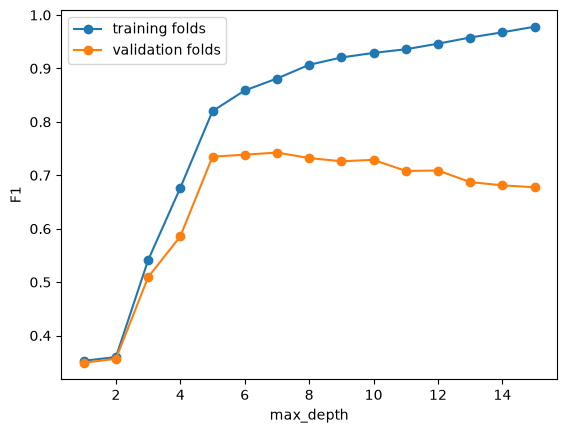

In [18]:
depths = range(1, 16)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=0), Xc_train, yc_train,
    param_name="max_depth", param_range=depths, cv=cv, scoring="f1")

plt.plot(depths, train_scores.mean(axis=1), "o-", label="training folds")
plt.plot(depths, val_scores.mean(axis=1), "o-", label="validation folds")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.legend()
plt.show()

This picture is worth remembering:

+ **Shallow trees (depth 1-3) underfit:** both scores are low. The model is too simple to capture the pattern.
+ **Around depth 5-7** the validation score peaks at about 0.74.
+ **Deeper trees overfit:** the training score keeps climbing towards 1 while the validation score falls. The tree is memorising the training customers.

The best setting is where the **validation** score peaks, never where the training score does. The gap between the two curves is a direct measure of overfitting.

## 8. Tuning hyperparameters

Trying values one by one gets tedious with more than one hyperparameter. Scikit-learn automates it.

### Grid search

`GridSearchCV` tries every combination in a grid, scores each with cross-validation on the training set, and then refits the best one on the whole training set. On a pipeline, a parameter is addressed as `step name` + two underscores + `parameter name`.

In [19]:
param_grid = {
    "model__n_neighbors": [1, 3, 5, 10, 20, 40],
    "model__weights": ["uniform", "distance"],
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_root_mean_squared_error")
grid.fit(Xr_train, yr_train)

print("Best settings:", grid.best_params_)
print(f"Best cross-validated RMSE: {-grid.best_score_:,.0f}")

Best settings: {'model__n_neighbors': 10, 'model__weights': 'distance'}
Best cross-validated RMSE: 2,749


Scikit-learn always maximises the score, so error metrics come negated (`neg_root_mean_squared_error`); flip the sign to read them. `cv_results_` holds every combination, which is useful to see how much the choice matters:

In [20]:
results = pd.DataFrame(grid.cv_results_)
results["rmse"] = -results["mean_test_score"]
results.pivot(index="param_model__n_neighbors", columns="param_model__weights", values="rmse").round(0)

param_model__weights,distance,uniform
param_model__n_neighbors,,
1,3378.0,3378.0
3,2978.0,3000.0
5,2841.0,2851.0
10,2749.0,2755.0
20,2782.0,3420.0
40,3134.0,4486.0


Only after choosing do we touch the test set, **once**. `grid` behaves like the best pipeline refitted on all the training data.

In [21]:
print(f"Test RMSE of the tuned pipeline: {root_mean_squared_error(yr_test, grid.predict(Xr_test)):,.0f}")

Test RMSE of the tuned pipeline: 3,209


The test error (3,209) is higher than the cross-validated one (2,749). That is normal: the best of 12 combinations was picked partly because it got lucky on these folds. It is still better than the untuned 3,699, but not as good as dropping the redundant features by hand in section 4. Tuning settings cannot fully make up for bad features.

### A grid on several hyperparameters

On churn, a decision tree with three hyperparameters: 7 × 3 × 2 = 42 combinations, each trained 5 times.

In [22]:
tree_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"],
}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=0), tree_grid, cv=cv, scoring="f1")
tree_search.fit(Xc_train, yc_train)

print("Best settings:", tree_search.best_params_)
print(f"Best cross-validated F1: {tree_search.best_score_:.3f}")
pd.DataFrame(tree_search.cv_results_).sort_values("rank_test_score")[
    ["param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_score", "std_test_score"]].head()

Best settings: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}
Best cross-validated F1: 0.739


,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score
13,8,5,NaN,0.738801,0.034109
9,6,1,NaN,0.738517,0.017876
10,6,5,NaN,0.738249,0.035099
16,10,5,NaN,0.736612,0.032495
7,5,5,NaN,0.735237,0.025019


The top five are within 0.004 of each other, far less than their standard deviations across folds (about 0.02-0.035). Any of them is a reasonable choice; do not read much into which one came first. `min_samples_leaf` (each leaf must hold at least that many customers) is another way to stop a tree from memorising individual rows.

In [23]:
best_tree = tree_search.best_estimator_
y_pred = best_tree.predict(Xc_test)
print(f"Test F1 {f1_score(yc_test, y_pred):.3f}, recall {recall_score(yc_test, y_pred):.3f}, precision {precision_score(yc_test, y_pred):.3f}")

Test F1 0.853, recall 0.818, precision 0.892


### Random search

A grid grows fast: 5 hyperparameters with 5 values each is 3,125 combinations. `RandomizedSearchCV` tries a fixed number of random combinations instead, and can sample from a continuous range. For a parameter like logistic regression's `C`, which matters on a multiplicative scale (0.01, 0.1, 1, 10), sample from a log-uniform distribution.

In [24]:
logreg_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
param_dist = {
    "logisticregression__C": loguniform(1e-3, 1e2),
    "logisticregression__class_weight": [None, "balanced"],
}
random_search = RandomizedSearchCV(logreg_pipe, param_dist, n_iter=20, cv=cv, scoring="f1", random_state=0)
random_search.fit(Xc_train, yc_train)

print("Best settings:", random_search.best_params_)
print(f"Best cross-validated F1: {random_search.best_score_:.3f}")

Best settings: {'logisticregression__C': np.float64(0.5547119471592125), 'logisticregression__class_weight': 'balanced'}
Best cross-validated F1: 0.478


The search picked `class_weight="balanced"`, which is the subject of the next section. Even tuned, logistic regression's F1 stays well below the tree's: tuning improves a model, it does not turn it into a different one.

## 9. Imbalanced data

Only 14.5% of customers churn. When one class is rare, three things need care: how you split, how you score, and how much the model cares about the rare class.

### Stratify every split

Plain `KFold` cuts the data into consecutive chunks, so the share of churners varies from fold to fold. `StratifiedKFold` keeps it the same in every fold, which makes the fold scores comparable. `train_test_split(..., stratify=y)` does the same for the test split.

In [25]:
for name, splitter in [("KFold", KFold(n_splits=5)), ("StratifiedKFold", StratifiedKFold(n_splits=5))]:
    shares = [yc_train.iloc[val_idx].mean() for _, val_idx in splitter.split(Xc_train, yc_train)]
    print(f"{name:>16}: churn share per fold {np.round(shares, 3)}")

           KFold: churn share per fold [0.134 0.14  0.152 0.152 0.146]
 StratifiedKFold: churn share per fold [0.144 0.144 0.146 0.146 0.144]


With a classifier, `cross_val_score(..., cv=5)` already stratifies. Pass a `StratifiedKFold` explicitly when you also want to shuffle or fix the random state.

### Score with a metric that sees the rare class

Accuracy is the default `scoring`. On churn it says logistic regression is fine; F1 says otherwise.

In [26]:
logreg = make_pipeline(StandardScaler(), LogisticRegression())
print("Accuracy per fold:", cross_val_score(logreg, Xc_train, yc_train, cv=cv).round(3))
print("F1 per fold:      ", cross_val_score(logreg, Xc_train, yc_train, cv=cv, scoring="f1").round(3))

Accuracy per fold: [0.84  0.878 0.864 0.872 0.852]
F1 per fold:       [0.245 0.384 0.333 0.304 0.213]


Useful values for `scoring=` on imbalanced data: `"f1"`, `"recall"`, `"precision"`, `"balanced_accuracy"` and `"average_precision"` (the area under the precision-recall curve). Choose the one that matches the business cost of each mistake, and use the same one in your searches.

### Class weights

`class_weight="balanced"` makes each mistake on the rare class cost more during training, in proportion to how rare it is. Most scikit-learn classifiers accept it, including logistic regression, trees, random forests and SVMs.

In [27]:
for weight in [None, "balanced"]:
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=weight)).fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    print(f"class_weight={str(weight):>8}: accuracy {accuracy_score(yc_test, pred):.3f}  "
          f"recall {recall_score(yc_test, pred):.3f}  precision {precision_score(yc_test, pred):.3f}  "
          f"F1 {f1_score(yc_test, pred):.3f}")

class_weight=    None: accuracy 0.868  recall 0.231  precision 0.622  F1 0.337
class_weight=balanced: accuracy 0.760  recall 0.785  precision 0.353  F1 0.487


Recall jumps from 0.23 to 0.79: the model now finds four in five churners instead of one in four. The price is precision (more false alarms) and accuracy, which falls because the model now predicts "churn" far more often. Whether that trade is worth it is a business decision, exactly like moving the threshold in Week 4 Day 5.

### Moving the threshold

Class weights change the model; the threshold changes how its probabilities are turned into decisions. Both push in the same direction. On the tuned tree:

In [28]:
proba = best_tree.predict_proba(Xc_test)[:, 1]
for threshold in [0.5, 0.3]:
    pred = (proba >= threshold).astype(int)
    print(f"threshold {threshold}: recall {recall_score(yc_test, pred):.3f}  precision {precision_score(yc_test, pred):.3f}")

threshold 0.5: recall 0.818  precision 0.892
threshold 0.3: recall 0.851  precision 0.786


### Resampling

A third option changes the data: **oversample** the rare class (repeat its rows, or create synthetic ones with SMOTE) or **undersample** the common one. The `imbalanced-learn` library provides these, with a pipeline that applies them during `fit` only.

The rule that matters: **resample the training data only, inside each cross-validation fold.** Resampling before the split puts copies of the same customer in both training and test data, and the scores become meaningless. Try class weights first: they are built in, need no extra library and often work as well.

## Summary: what to do when

| Situation | What to do |
|---|---|
| Text categories | One-hot encode (`OneHotEncoder`, `get_dummies`); ordinal only if the order is real |
| Missing values | Ask what the gap means first; then fill (`SimpleImputer`) or flag it |
| Features on different scales | Scale for KNN, SVM, logistic regression; not needed for trees |
| Features that repeat each other | Check correlations; drop one of each highly correlated pair |
| A relationship a straight line cannot capture | Build the feature that captures it, from domain knowledge or `PolynomialFeatures` |
| More than one preprocessing step | Put everything in a `Pipeline`, with a `ColumnTransformer` for mixed columns |
| Choosing hyperparameters | `GridSearchCV` or `RandomizedSearchCV` on the training set; test set once at the end |
| Training score far above validation | Overfitting: simplify the model (depth, leaf size, regularisation) |
| A rare class | Stratify, score with F1 / recall / balanced accuracy, try `class_weight="balanced"`, move the threshold |

## Appendix

### A.1 Ordinal encoding and binning

When the order is real, `OrdinalEncoder` with an explicit order turns categories into 0, 1, 2. Without `categories=` it numbers them alphabetically, which is rarely the order you want.

In [29]:
encoder = OrdinalEncoder(categories=[["Junior", "Senior"]])
encoder.fit_transform(raw[["Experience"]])[:5].ravel()

array([1., 0., 1., 0., 0.])

**Binning** goes the other way: it turns a number into groups. `pd.cut` makes equal-width bins; `pd.qcut` makes bins with the same number of rows in each. Binning can help when only the range matters (an age group, a price band), at the cost of throwing away detail inside each bin.

In [30]:
pd.DataFrame({
    "Height": raw["Height"].round(1),
    "equal width (cut)": pd.cut(raw["Height"], 3, labels=["short", "average", "tall"]),
    "equal count (qcut)": pd.qcut(raw["Height"], 3, labels=["short", "average", "tall"]),
}).head()

,Height,equal width (cut),equal count (qcut)
0,160.2,short,short
1,153.1,short,short
2,166.9,average,average
3,174.0,average,tall
4,180.3,tall,tall


### A.2 Learning curves: would more data help?

A validation curve varies a hyperparameter; a **learning curve** varies the amount of training data. If the validation score is still rising at the right-hand end, more data would probably help. If the two curves have met and flattened, more data will not, and you need better features or a more flexible model instead.

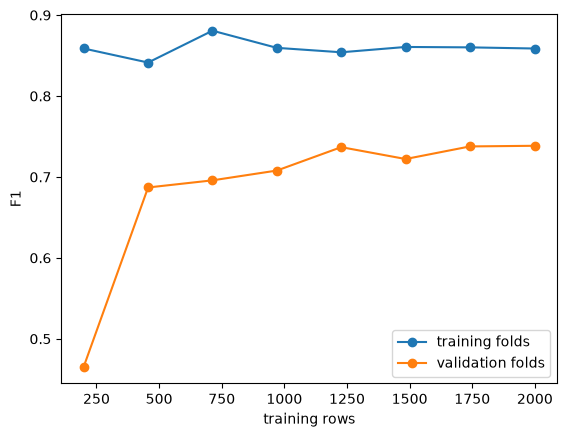

In [31]:
sizes, train_lc, val_lc = learning_curve(
    DecisionTreeClassifier(max_depth=6, random_state=0), Xc_train, yc_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=cv, scoring="f1")

plt.plot(sizes, train_lc.mean(axis=1), "o-", label="training folds")
plt.plot(sizes, val_lc.mean(axis=1), "o-", label="validation folds")
plt.xlabel("training rows")
plt.ylabel("F1")
plt.legend()
plt.show()

### A.3 Training error and generalisation error

The **training error** $E_{in}$ is the error on the data the model learnt from. The **generalisation error** $E_{out}$ is the error on new data, which is what we care about. $E_{in}$ is almost always smaller, because the model was fitted to those very rows.

Learning theory says the gap $E_{out} - E_{in}$ grows with the **complexity** of the model and shrinks with the **amount of data**. That is the whole story of this notebook in one sentence: a deeper tree has more complexity, so its gap is larger (section 7), and more rows shrink the gap (A.2). Cross-validation and a held-out test set are how we estimate $E_{out}$ without waiting for new data.

There are three standard cures for a large gap: choose the complexity with cross-validation (section 8), **regularise** (Ridge and Lasso from Week 4 Day 3, `C` in logistic regression and SVMs), and **combine many models**, which is tomorrow's lesson on ensembles.